In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import mlflow
import optuna
from sklearn.metrics import root_mean_squared_error
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import TargetEncoder
from sklearn.inspection import permutation_importance
import shap
import lightgbm as lgb

from src.data.etl import (
    ItemCategoryLoader,
    ItemsLoader,
    ShopsLoader,
    TrainLoader,
    DfFinalLoader,
    ForSubmissionLoader,
)

from src.models.baseline_model import BaseLineModel, ZerosModel, OnesModel, SeasonalModel, StatsSeasonalModel, CategorySeasonalModel, ShopCatTrendModel
from src.validation.chema import validation_chema, log_validation
from src.visualization.plot_functions import plot_time_dataframe

mlflow.set_tracking_uri("http://127.0.0.1:5000")
#mlflow.set_tracking_uri("http://mlflow:5000")
mlflow.set_experiment("Predict Future Sales")

print("Tracking URI:", mlflow.get_tracking_uri())

Tracking URI: http://127.0.0.1:5000


In [2]:
project_root = Path.cwd().parent
raw_path = project_root / "data" / "raw"
processed_path = project_root / "data" / "processed"
models_path = project_root / "data" / "models" / "validation"

items_df = ItemsLoader(raw_data_path=raw_path, cache_path=processed_path).load()
item_cats_df = ItemCategoryLoader(raw_data_path=raw_path, cache_path=processed_path).load()
shops_df = ShopsLoader(raw_data_path=raw_path, cache_path=processed_path).load()
train_df = TrainLoader(raw_data_path=raw_path, cache_path=processed_path).load()
final_df = DfFinalLoader(cache_path=processed_path, shops=shops_df, items=items_df, item_cats=item_cats_df, train=train_df).load()
subm_df = ForSubmissionLoader(raw_data_path=raw_path, cache_path=processed_path, shops=shops_df, items=items_df).load()
columns_to_group = ['corrected_item_id', 'corrected_shop_id', 'date_block_num']
other_columns = set(final_df.columns) - {'corrected_item_id', 'corrected_shop_id', 'date_block_num', 'item_cnt_day'}
final_df = final_df.groupby(['corrected_item_id', 'corrected_shop_id', 'date_block_num'], as_index=False).agg({col: (
        'sum' if col == 'item_cnt_day' 
        else 'mean' if col == 'no_inflation_price'
        else 'first'
    )
    for col in final_df.columns
    if col not in columns_to_group})



In [3]:
subm_df['date_block_num'] = 34
subm_df['date'] = pd.to_datetime('2015-11-29', format='%Y-%m-%d')
subm_df['year'] = subm_df['date'].dt.year
subm_df['month'] = subm_df['date'].dt.month
subm_df['week_day'] = subm_df['date'].dt.weekday
subm_df['day'] = 0

subm_df = (
    subm_df
    .merge(
        items_df[
            [ "corrected_item_id", "item_category_id", "item_name"]
        ],
        on="corrected_item_id",
        how="left"
    )
    .merge(
        item_cats_df[
            ["item_category_id", "main_category"]
        ],
        on="item_category_id",
        how="left"
    )
    .merge(
        shops_df[
            ["corrected_shop_id", "city"]
        ],
        on="corrected_shop_id",
        how="left"
    )
    .drop(columns=["item_category_id"])
)

subm_df['item_price'] = 0
subm_df['item_cnt_day'] = 0
subm_df['no_inflation_price'] = 0

for_missing_items = subm_df.groupby(['corrected_item_id']).agg(main_category=('main_category', 'first')).reset_index()
cat_sales_map = final_df.groupby(['main_category']).agg(sales=("item_cnt_day", 'sum'))
cat_sales_map['num'] = final_df.groupby(['main_category']).agg(num=("corrected_item_id", 'nunique'))['num']
cat_sales_map['item_cnt_day'] = cat_sales_map['sales'] / cat_sales_map['num']
for_missing_items = for_missing_items.merge(cat_sales_map.reset_index()[['main_category', 'item_cnt_day']], on='main_category', how='left')
for_missing_items = for_missing_items[~for_missing_items['corrected_item_id'].isin(final_df['corrected_item_id'].unique())]
missing_items_map = for_missing_items.set_index('corrected_item_id')['item_cnt_day']
mask = ~subm_df['corrected_item_id'].isin(final_df['corrected_item_id'].unique())
subm_df.loc[mask, 'item_cnt_day'] = subm_df.loc[mask, 'corrected_item_id'].map(missing_items_map)


C:\Users\user\AppData\Local\Temp\ipykernel_35436\3919423716.py:46: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[ 96.72953904 374.15606936 168.8916185  ... 125.43652531 324.12699906
  96.72953904]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  subm_df.loc[mask, 'item_cnt_day'] = subm_df.loc[mask, 'corrected_item_id'].map(missing_items_map)


In [4]:
shop_sales = final_df.groupby(["corrected_shop_id"], as_index=False).agg(item_cnt_day=("item_cnt_day", "sum")).sort_values(by=["item_cnt_day"], ascending=False).reset_index(drop=True)
shop_map = pd.Series(shop_sales.index.values, index=shop_sales["corrected_shop_id"])
final_df["corrected_shop_id"] = final_df["corrected_shop_id"].map(shop_map)
subm_df["corrected_shop_id"] = subm_df["corrected_shop_id"].map(shop_map)

category_sales = final_df.groupby(["main_category"], as_index=False).agg(item_cnt_day=("item_cnt_day", "sum")).sort_values(by=["item_cnt_day"], ascending=False).reset_index(drop=True)
category_map = pd.Series(category_sales.index.values, index=category_sales["main_category"])
final_df["main_category"] = final_df["main_category"].map(category_map)
subm_df["main_category"] = subm_df["main_category"].map(category_map)


city_sales = final_df.groupby(["city"], as_index=False).agg(item_cnt_day=("item_cnt_day", "sum")).sort_values(by=["item_cnt_day"], ascending=False).reset_index(drop=True)
city_map = pd.Series(city_sales.index.values, index=city_sales["city"])
final_df["city"] = final_df["city"].map(city_map)
subm_df["city"] = subm_df["city"].map(city_map)


final_df = pd.concat((final_df, subm_df[final_df.columns]), ignore_index=True)
item_sales = final_df.groupby(["corrected_item_id"], as_index=False).agg(item_cnt_day=("item_cnt_day", "sum")).sort_values(by=["item_cnt_day"], ascending=False).reset_index(drop=True)
item_map = pd.Series(item_sales.index.values, index=item_sales["corrected_item_id"])
final_df["corrected_item_id"] = final_df["corrected_item_id"].map(item_map)
subm_df["corrected_item_id"] = subm_df["corrected_item_id"].map(item_map)







final_df['is_ticket'] = final_df['item_name'].str.startswith('Билет "ИгроМир', na=False).astype(int)
final_df['is_bag'] = final_df['item_name'].str.startswith('Фирменный пакет майка', na=False).astype(int)



month_forms = {
    1: [
        'январь', 'января', 'январе', 'январю', 'январём', 'январем'
    ],
    2: [
        'февраль', 'февраля', 'феврале', 'февралю'
    ],
    3: [
        'март', 'марта', 'марте', 'марту'
    ],
    4: [
        'апрель', 'апреля', 'апреле', 'апрелю'
    ],
    5: [
        'май', 'мая', 'мае', 'маю'
    ],
    6: [
        'июнь', 'июня', 'июне', 'июню'
    ],
    7: [
        'июль', 'июля', 'июле', 'июлю'
    ],
    8: [
        'август', 'августа', 'августе', 'августу'
    ],
    9: [
        'сентябрь', 'сентября', 'сентябре', 'сентябрю'
    ],
    10: [
        'октябрь', 'октября', 'октябре', 'октябрю'
    ],
    11: [
        'ноябрь', 'ноября', 'ноябре', 'ноябрю'
    ],
    12: [
        'декабрь', 'декабря', 'декабре', 'декабрю'
    ]
}

def get_month_till_event(row):
    if 'билет' not in str(row['main_category']).lower():
        return 999

    name = str(row['item_name']).lower()

    for month, forms in month_forms.items():
        if any(form in name for form in forms):
            return (month - int(row['month'])) % 12

    return 999


final_df['month_till_event'] = final_df.apply(get_month_till_event, axis=1)




def add_lag_feature(df, lags, col):
    tmp = df[['date_block_num', 'corrected_shop_id', 'corrected_item_id', col]]
    for i in lags:
        shifted = tmp.copy()
        shifted.columns = ['date_block_num', 'corrected_shop_id', 'corrected_item_id', col+'_lag_'+str(i)]
        shifted['date_block_num'] += i
        df = pd.merge(df, shifted, on=['date_block_num', 'corrected_shop_id', 'corrected_item_id'], how="left")
    return df



def add_window_feature(df, windows, col):
    for window in windows:
        df[col+'_window_'+str(window)] = df[[col+'_lag_' + str(i) for i in range(1, window + 1)]].mean(axis=1)
    return df




final_df['revenue'] = final_df['item_cnt_day'] * final_df['no_inflation_price']



revenue_for_city = final_df.groupby(['city', 'date_block_num'], as_index=False).agg(city_revenue=("revenue", "sum"))
final_df = final_df.merge(revenue_for_city, on=['city', 'date_block_num'], how="left")
final_df = add_lag_feature(final_df, [1, 2, 3, 4, 5, 6, 12], 'city_revenue').fillna(0)
final_df = add_window_feature(final_df, [1, 2, 3, 4, 5, 6,], 'city_revenue').fillna(0)

revenue_for_shops = final_df.groupby(['corrected_shop_id', 'date_block_num'], as_index=False).agg(shop_revenue=("revenue", "sum"))
final_df = final_df.merge(revenue_for_shops, on=['corrected_shop_id', 'date_block_num'], how="left")
final_df = add_lag_feature(final_df, [1, 2, 3, 4, 5, 6, 12], 'shop_revenue').fillna(0)
final_df = add_window_feature(final_df, [1, 2, 3, 4, 5, 6,], 'shop_revenue').fillna(0)


revenue_for_cat = final_df.groupby(['main_category', 'date_block_num'], as_index=False).agg(cat_revenue=("revenue", "sum"))
final_df = final_df.merge(revenue_for_cat, on=["main_category", 'date_block_num'], how="left")
final_df = add_lag_feature(final_df, [1, 2, 3, 4, 5, 6, 12], 'cat_revenue').fillna(0)
final_df = add_window_feature(final_df, [1, 2, 3, 4, 5, 6,], 'cat_revenue').fillna(0)

revenue_for_cat_in_shops = final_df.groupby(['main_category', 'corrected_shop_id', 'date_block_num'], as_index=False).agg(cat_shop_revenue=("revenue", "sum"))
final_df = final_df.merge(revenue_for_cat_in_shops, on=['main_category', 'corrected_shop_id', 'date_block_num'], how="left")
final_df = add_lag_feature(final_df, [1, 2, 3, 4, 5, 6, 12], 'cat_shop_revenue').fillna(0)
final_df = add_window_feature(final_df, [1, 2, 3, 4, 5, 6,], 'cat_shop_revenue').fillna(0)


revenue_for_items = final_df.groupby(['corrected_item_id', 'date_block_num'], as_index=False).agg(item_revenue=("revenue", "sum"))
final_df = final_df.merge(revenue_for_items, on=['corrected_item_id', 'date_block_num'], how="left")
final_df = add_lag_feature(final_df, [1, 2, 3, 4, 5, 6, 12], 'item_revenue').fillna(0)
final_df = add_window_feature(final_df, [1, 2, 3, 4, 5, 6,], 'item_revenue').fillna(0)


revenue_for_items_in_shop = final_df.groupby(['corrected_item_id', 'corrected_shop_id', 'date_block_num'], as_index=False).agg(item_shop_revenue=("revenue", "sum"))
final_df = final_df.merge(revenue_for_items_in_shop, on=['corrected_item_id', 'corrected_shop_id', 'date_block_num'], how="left")
final_df = add_lag_feature(final_df, [1, 2, 3, 4, 5, 6, 12], 'item_shop_revenue').fillna(0)
final_df = add_window_feature(final_df, [1, 2, 3, 4, 5, 6,], 'item_shop_revenue').fillna(0)





sales_for_category = final_df.groupby(['main_category', 'date_block_num'], as_index=False).agg(category_sales=("item_cnt_day", "sum"))
final_df = final_df.merge(sales_for_category, on=["main_category", 'date_block_num'], how="left")
final_df = add_lag_feature(final_df, [1, 2, 3, 4, 5, 6, 12], 'category_sales').fillna(0)
final_df = add_window_feature(final_df, [1, 2, 3, 4, 5, 6,], 'category_sales').fillna(0)



sales_for_shop = final_df.groupby(['corrected_shop_id', 'date_block_num'], as_index=False).agg(shop_sales=("item_cnt_day", "sum"))
final_df = final_df.merge(sales_for_shop, on=["corrected_shop_id", 'date_block_num'], how="left")
final_df = add_lag_feature(final_df, [1, 2, 3, 4, 5, 6, 12], 'shop_sales').fillna(0)
final_df = add_window_feature(final_df, [1, 2, 3, 4, 5, 6,], 'shop_sales').fillna(0)

sales_for_category_in_shop = final_df.groupby(['main_category', 'corrected_shop_id', 'date_block_num'], as_index=False).agg(category_shop_sales=("item_cnt_day", "sum"))
final_df = final_df.merge(sales_for_category_in_shop, on=["main_category", 'corrected_shop_id', 'date_block_num'], how="left")
final_df = add_lag_feature(final_df, [1, 2, 3, 4, 5, 6, 12], 'category_shop_sales').fillna(0)
final_df = add_window_feature(final_df, [1, 2, 3, 4, 5, 6,], 'category_shop_sales').fillna(0)

sales_for_item_in_shop = final_df.groupby(['corrected_item_id', 'corrected_shop_id', 'date_block_num'], as_index=False).agg(item_shop_sales=("item_cnt_day", "sum"))
final_df = final_df.merge(sales_for_item_in_shop, on=["corrected_item_id", 'corrected_shop_id', 'date_block_num'], how="left")
final_df = add_lag_feature(final_df, [1, 2, 3, 4, 5, 6, 12], 'item_shop_sales').fillna(0)
final_df = add_window_feature(final_df, [1, 2, 3, 4, 5, 6,], 'item_shop_sales').fillna(0)

sales_for_month_block = final_df.groupby(['date_block_num'], as_index=False).agg(month_block_sales=("item_cnt_day", "sum"))
final_df = final_df.merge(sales_for_month_block, on=['date_block_num'], how="left")
final_df = add_lag_feature(final_df, [1, 2, 3, 4, 5, 6, 12], 'month_block_sales').fillna(0)
final_df = add_window_feature(final_df, [1, 2, 3, 4, 5, 6,], 'month_block_sales').fillna(0)

sales_for_item = final_df.groupby(['corrected_item_id', 'date_block_num'], as_index=False).agg(item_sales=("item_cnt_day", "sum"))
final_df = final_df.merge(sales_for_item, on=["corrected_item_id", 'date_block_num'], how="left")
final_df = add_lag_feature(final_df, [1, 2, 3, 4, 5, 6, 12], 'item_sales').fillna(0)
final_df = add_window_feature(final_df, [1, 2, 3, 4, 5, 6,], 'item_sales').fillna(0)




last_sale_map = {}
final_df['last_sale'] = -1
for idx, row in final_df.iterrows():
    key = str(row.corrected_item_id)+' '+str(row.corrected_shop_id)
    if key not in last_sale_map:
        last_sale_map[key] = row.date_block_num
    else:
        last_date_block_num = last_sale_map[key]
        final_df.at[idx, 'last_sale'] = row.date_block_num - last_date_block_num
        last_sale_map[key] = row.date_block_num



final_df['item_name_len'] = final_df['item_name'].apply(len)

final_df = add_lag_feature(final_df, [i for i in range(1, 13)], 'item_cnt_day').fillna(0)

final_df['window_12'] = final_df[['item_cnt_day_lag_' + str(i) for i in range(1, 13)]].mean(axis=1)

final_df['window_12'] = final_df[['item_cnt_day_lag_' + str(i) for i in range(1, 13)]].mean(axis=1)

final_df['window_3'] = final_df[['item_cnt_day_lag_' + str(i) for i in range(1, 4)]].mean(axis=1)

final_df['window_6'] = final_df[['item_cnt_day_lag_' + str(i) for i in range(1, 7)]].mean(axis=1)

final_df['item_name_len'] = final_df['item_name'].apply(len)

final_df = add_lag_feature(final_df, [1, 2], 'item_price').fillna(0)
final_df['price_increase'] = (final_df['item_price_lag_1'] - final_df['item_price_lag_2']) / (final_df['item_price_lag_2'] + 1)

final_df['is_holiday'] = ((final_df['month'] == 1) | (final_df['month'] == 11)).astype(int)

final_df['previous_peak'] = (
    final_df.assign(_row_order=range(len(final_df)))
    .sort_values('date_block_num')
    .groupby(['corrected_shop_id', 'corrected_item_id'])['item_cnt_day']
    .transform(lambda x: x.cummax().shift(1))
    .sort_index()
    .fillna(-1)
)

final_df['sales_increase'] = 2 * final_df['item_cnt_day_lag_1'] - final_df['item_cnt_day_lag_2']

final_df['months_since_last_peak'] = (
    final_df.sort_values('date_block_num')
    .groupby(['corrected_shop_id', 'corrected_item_id'], group_keys=False)
    .apply(
        lambda g: (
            g['date_block_num']
            - g['date_block_num'].where(
                g['item_cnt_day'].shift(1).cummax()
                .eq(g['item_cnt_day'].shift(1))
            ).ffill()
        )
    )
    .sort_index()
    .fillna(-1)
)



age_df = final_df.groupby(['corrected_item_id']).agg(first_bought_month=('date_block_num', 'min'))
final_df = pd.merge(final_df, age_df, on=['corrected_item_id'], how="left")
final_df['age'] = final_df['date_block_num'] - final_df['first_bought_month']





C:\Users\user\AppData\Local\Temp\ipykernel_35436\1503229330.py:233: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


In [24]:
y = final_df['item_cnt_day']

In [23]:
features=['corrected_item_id',
 'item_cnt_day_lag_1',
 'category_sales_window_6',
 'is_bag',
 'age',
 'category_sales_window_5',
 'item_shop_sales_window_1',
 'category_sales_window_3',
 'item_shop_sales_lag_1',
 'item_revenue_window_2',
 'category_sales_window_4',
 'item_shop_sales_window_6',
 'item_shop_sales_window_5',
 'month_till_event',
 'item_shop_sales_window_2',
 'window_6',
 'category_sales_window_2',
 'corrected_shop_id',
 'city',
 'item_shop_sales_window_3',
 'item_shop_sales_window_4',
 'item_sales_window_6',
 'item_sales_window_5',
 'previous_peak',
 'item_sales_window_3',
 'window_3',
 'item_revenue_lag_2',
 'window_12',
 'item_sales_lag_3',
 'cat_revenue_window_6',
 'category_shop_sales_lag_2',
 'item_shop_revenue_lag_1',
 'item_revenue_window_5',
 'item_shop_revenue_window_3',
 'shop_revenue_lag_12',
 'item_shop_sales_lag_3',
 'main_category',
 'item_name_len',
 'cat_shop_revenue_lag_2',
 'cat_revenue_window_4',
 'item_shop_revenue_lag_5',
 'shop_revenue_lag_2',
 'item_shop_revenue_window_1',
 'item_cnt_day_lag_2',
 'item_shop_sales_lag_2',
 'shop_sales_lag_1',
 'item_revenue_window_3',
 'item_cnt_day_lag_3',]

In [25]:
final_df_copy = final_df.copy()

In [26]:
final_df = final_df[final_df['is_ticket'] == 0]

In [27]:

params = {'n_estimators': 150, 'max_depth': 150, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 0.5, 'bootstrap': True, "random_state":0, "n_jobs":-1, 'criterion':"squared_error"}
model = RandomForestRegressor(**params)
x_train, y_train = final_df[(final_df['date_block_num'] < 34) & (final_df['date_block_num'] > 21)][features], final_df[(final_df['date_block_num'] < 34) & (final_df['date_block_num'] > 21)]['item_cnt_day']

model.fit(x_train, y_train)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",150
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",150
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",0.5
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples

In [28]:
preds = model.predict(final_df[final_df['date_block_num'] == 34][features])

In [35]:
preds = preds.clip(0, 20)

In [30]:
df_preds = final_df[final_df['date_block_num'] == 34]
df_preds['item_cnt_month'] = preds

C:\Users\user\AppData\Local\Temp\ipykernel_35436\3972992788.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_preds['item_cnt_month'] = preds


In [31]:
answers = subm_df.merge(df_preds[['item_cnt_month', 'corrected_item_id', 'corrected_shop_id']], on=['corrected_item_id', 'corrected_shop_id'], how='left')

In [32]:
preds = answers[['ID', 'item_cnt_month']]

print(preds.head())

   ID  item_cnt_month
0   0        1.566667
1   1       20.000000
2   2        1.560000
3   3        1.066667
4   4       20.000000


In [33]:
preds = preds.drop_duplicates(subset='ID', keep='first')

In [34]:
preds.to_csv('submission.csv', index=False)

In [ ]:
model = lgb.LGBMRegressor(
    objective="regression",
    max_depth=8,
    n_estimators=1500,
    learning_rate=0.1,
    min_child_weight=1e-3,
    colsample_bytree=0.8,
    subsample=0.8,
    subsample_freq=1,
    random_state=42,
    verbosity=-1
)
x_train, y_train = final_df[(final_df['date_block_num'] < 32) & (final_df['date_block_num'] > 19)][features], final_df[(final_df['date_block_num'] < 32) & (final_df['date_block_num'] > 19)]['item_cnt_day']
x_test, y_test = final_df[(final_df['date_block_num'] == 32)][features], final_df[(final_df['date_block_num'] == 32)]['item_cnt_day']
model.fit(x_train, y_train)
preds = model.predict(x_test)

In [36]:
root_mean_squared_error(preds, y_test)

16.288253892820233

In [20]:
features = ['corrected_item_id',
 'corrected_shop_id',
 'date_block_num',
 'year',
 'month',
 'main_category',
 'city',
 'is_ticket',
 'is_bag',
 'first_bought_month',
 'age',
 'month_till_event',
 'city_revenue_lag_1',
 'city_revenue_lag_2',
 'city_revenue_lag_3',
 'city_revenue_lag_4',
 'city_revenue_lag_5',
 'city_revenue_lag_6',
 'city_revenue_lag_12',
 'city_revenue_window_1',
 'city_revenue_window_2',
 'city_revenue_window_3',
 'city_revenue_window_4',
 'city_revenue_window_5',
 'city_revenue_window_6',
 'shop_revenue_lag_1',
 'shop_revenue_lag_2',
 'shop_revenue_lag_3',
 'shop_revenue_lag_4',
 'shop_revenue_lag_5',
 'shop_revenue_lag_6',
 'shop_revenue_lag_12',
 'shop_revenue_window_1',
 'shop_revenue_window_2',
 'shop_revenue_window_3',
 'shop_revenue_window_4',
 'shop_revenue_window_5',
 'shop_revenue_window_6',
 'cat_revenue_lag_1',
 'cat_revenue_lag_2',
 'cat_revenue_lag_3',
 'cat_revenue_lag_4',
 'cat_revenue_lag_5',
 'cat_revenue_lag_6',
 'cat_revenue_lag_12',
 'cat_revenue_window_1',
 'cat_revenue_window_2',
 'cat_revenue_window_3',
 'cat_revenue_window_4',
 'cat_revenue_window_5',
 'cat_revenue_window_6',
 'cat_shop_revenue_lag_1',
 'cat_shop_revenue_lag_2',
 'cat_shop_revenue_lag_3',
 'cat_shop_revenue_lag_4',
 'cat_shop_revenue_lag_5',
 'cat_shop_revenue_lag_6',
 'cat_shop_revenue_lag_12',
 'cat_shop_revenue_window_1',
 'cat_shop_revenue_window_2',
 'cat_shop_revenue_window_3',
 'cat_shop_revenue_window_4',
 'cat_shop_revenue_window_5',
 'cat_shop_revenue_window_6',
 'item_revenue_lag_1',
 'item_revenue_lag_2',
 'item_revenue_lag_3',
 'item_revenue_lag_4',
 'item_revenue_lag_5',
 'item_revenue_lag_6',
 'item_revenue_lag_12',
 'item_revenue_window_1',
 'item_revenue_window_2',
 'item_revenue_window_3',
 'item_revenue_window_4',
 'item_revenue_window_5',
 'item_revenue_window_6',
 'item_shop_revenue_lag_1',
 'item_shop_revenue_lag_2',
 'item_shop_revenue_lag_3',
 'item_shop_revenue_lag_4',
 'item_shop_revenue_lag_5',
 'item_shop_revenue_lag_6',
 'item_shop_revenue_lag_12',
 'item_shop_revenue_window_1',
 'item_shop_revenue_window_2',
 'item_shop_revenue_window_3',
 'item_shop_revenue_window_4',
 'item_shop_revenue_window_5',
 'item_shop_revenue_window_6',
 'category_sales_lag_1',
 'category_sales_lag_2',
 'category_sales_lag_3',
 'category_sales_lag_4',
 'category_sales_lag_5',
 'category_sales_lag_6',
 'category_sales_lag_12',
 'category_sales_window_1',
 'category_sales_window_2',
 'category_sales_window_3',
 'category_sales_window_4',
 'category_sales_window_5',
 'category_sales_window_6',
 'shop_sales_lag_1',
 'shop_sales_lag_2',
 'shop_sales_lag_3',
 'shop_sales_lag_4',
 'shop_sales_lag_5',
 'shop_sales_lag_6',
 'shop_sales_lag_12',
 'shop_sales_window_1',
 'shop_sales_window_2',
 'shop_sales_window_3',
 'shop_sales_window_4',
 'shop_sales_window_5',
 'shop_sales_window_6',
 'category_shop_sales_lag_1',
 'category_shop_sales_lag_2',
 'category_shop_sales_lag_3',
 'category_shop_sales_lag_4',
 'category_shop_sales_lag_5',
 'category_shop_sales_lag_6',
 'category_shop_sales_lag_12',
 'category_shop_sales_window_1',
 'category_shop_sales_window_2',
 'category_shop_sales_window_3',
 'category_shop_sales_window_4',
 'category_shop_sales_window_5',
 'category_shop_sales_window_6',
 'item_shop_sales_lag_1',
 'item_shop_sales_lag_2',
 'item_shop_sales_lag_3',
 'item_shop_sales_lag_4',
 'item_shop_sales_lag_5',
 'item_shop_sales_lag_6',
 'item_shop_sales_lag_12',
 'item_shop_sales_window_1',
 'item_shop_sales_window_2',
 'item_shop_sales_window_3',
 'item_shop_sales_window_4',
 'item_shop_sales_window_5',
 'item_shop_sales_window_6',
 'month_block_sales_lag_1',
 'month_block_sales_lag_2',
 'month_block_sales_lag_3',
 'month_block_sales_lag_4',
 'month_block_sales_lag_5',
 'month_block_sales_lag_6',
 'month_block_sales_lag_12',
 'month_block_sales_window_1',
 'month_block_sales_window_2',
 'month_block_sales_window_3',
 'month_block_sales_window_4',
 'month_block_sales_window_5',
 'month_block_sales_window_6',
 'item_sales_lag_1',
 'item_sales_lag_2',
 'item_sales_lag_3',
 'item_sales_lag_4',
 'item_sales_lag_5',
 'item_sales_lag_6',
 'item_sales_lag_12',
 'item_sales_window_1',
 'item_sales_window_2',
 'item_sales_window_3',
 'item_sales_window_4',
 'item_sales_window_5',
 'item_sales_window_6',
 'last_sale',
 'item_name_len',
 'item_cnt_day_lag_1',
 'item_cnt_day_lag_2',
 'item_cnt_day_lag_3',
 'item_cnt_day_lag_4',
 'item_cnt_day_lag_5',
 'item_cnt_day_lag_6',
 'item_cnt_day_lag_7',
 'item_cnt_day_lag_8',
 'item_cnt_day_lag_9',
 'item_cnt_day_lag_10',
 'item_cnt_day_lag_11',
 'item_cnt_day_lag_12',
 'window_12',
 'window_3',
 'window_6',
 'item_price_lag_1',
 'item_price_lag_2',
 'price_increase',
 'is_holiday',
 'previous_peak',
 'sales_increase',
 'months_since_last_peak']

In [ ]:
params = {'n_estimators': 50, 'max_depth': 50, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 0.5, 'bootstrap': True, "random_state":0, "n_jobs":-1, 'criterion':"squared_error"}
model = RandomForestRegressor(**params)
x_train, y_train = final_df[(final_df['date_block_num'] < 32) & (final_df['date_block_num'] > 19)][features], final_df[(final_df['date_block_num'] < 32) & (final_df['date_block_num'] > 19)]['item_cnt_day']
x_test, y_test = final_df[(final_df['date_block_num'] == 32)][features], final_df[(final_df['date_block_num'] == 32)]['item_cnt_day']
model.fit(x_train, y_train)
preds = model.predict(x_test)

In [37]:
x_test, y_test = final_df[(final_df['date_block_num'] == 33)][features], final_df[(final_df['date_block_num'] == 33)]['item_cnt_day']
preds = model.predict(x_test)

In [38]:
root_mean_squared_error(y_test, preds)

1.734779115575174

In [28]:
result = permutation_importance(
    model,
    x_test,
    y_test,
    n_repeats=5,
    random_state=42,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

importance = pd.DataFrame({
    "feature": x_test.columns,
    "importance": result.importances_mean,
    "std": result.importances_std
}).sort_values("importance", ascending=False)

print(importance)

                        feature  importance       std
0             corrected_item_id    2.617152  0.471545
170          item_cnt_day_lag_1    2.094005  0.096109
102     category_sales_window_6    1.277074  0.086639
8                        is_bag    0.706955  0.039155
10                          age    0.682274  0.065531
..                          ...         ...       ...
22        city_revenue_window_4   -0.014868  0.004884
78      item_shop_revenue_lag_2   -0.019323  0.001350
89   item_shop_revenue_window_6   -0.063864  0.010335
190              sales_increase   -0.081760  0.000521
185            item_price_lag_1   -0.112883  0.059546

[192 rows x 3 columns]


In [32]:
importance['feature'].tolist()

['corrected_item_id',
 'item_cnt_day_lag_1',
 'category_sales_window_6',
 'is_bag',
 'age',
 'category_sales_window_5',
 'item_shop_sales_window_1',
 'category_sales_window_3',
 'item_shop_sales_lag_1',
 'item_revenue_window_2',
 'category_sales_window_4',
 'item_shop_sales_window_6',
 'item_shop_sales_window_5',
 'month_till_event',
 'item_shop_sales_window_2',
 'window_6',
 'category_sales_window_2',
 'corrected_shop_id',
 'city',
 'item_shop_sales_window_3',
 'item_shop_sales_window_4',
 'item_sales_window_6',
 'item_sales_window_5',
 'previous_peak',
 'item_sales_window_3',
 'window_3',
 'item_revenue_lag_2',
 'window_12',
 'item_sales_lag_3',
 'cat_revenue_window_6',
 'category_shop_sales_lag_2',
 'item_shop_revenue_lag_1',
 'item_revenue_window_5',
 'item_shop_revenue_window_3',
 'shop_revenue_lag_12',
 'item_shop_sales_lag_3',
 'main_category',
 'item_name_len',
 'cat_shop_revenue_lag_2',
 'cat_revenue_window_4',
 'item_shop_revenue_lag_5',
 'shop_revenue_lag_2',
 'item_shop_rev

In [ ]:
def rmse_by_month(df):
    return df.groupby("date_block_num").apply(
        lambda x: root_mean_squared_error(x["true_ans"], x["item_cnt_day"])
    )

In [10]:
compare_24_df = pd.DataFrame({
    "RandomForestRegresorAge": rmse_by_month(randomforest_results_24_age),
})

start_date_24 = randomforest_results_24_age['date'].iloc[0]
compare_24_df.index = pd.date_range(start=start_date_24, periods=len(compare_24_df), freq='MS').strftime('%Y-%m')
compare_24_df.mean()

C:\Users\user\AppData\Local\Temp\ipykernel_15652\945072317.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return df.groupby("date_block_num").apply(


RandomForestRegresorAge    6.149662
dtype: float64

In [148]:
randomforest_results_24 = randomforest_results_24.merge(
    final_df.groupby('corrected_item_id', as_index=False)
            .agg(item_name=('item_name', 'first')),
    on='corrected_item_id',
    how='left'
)

In [149]:
randomforest_results_24 = randomforest_results_24.merge(
    final_df.groupby(['corrected_shop_id'], as_index=False)
            .agg(city=('city', 'first'))[['corrected_shop_id', 'city']],
    on="corrected_shop_id",
    how="left"
)


In [150]:
reverse_city_map = pd.Series(city_map.index.values, index=city_map.values)

randomforest_results_24["city"] = randomforest_results_24["city"].map(reverse_city_map)

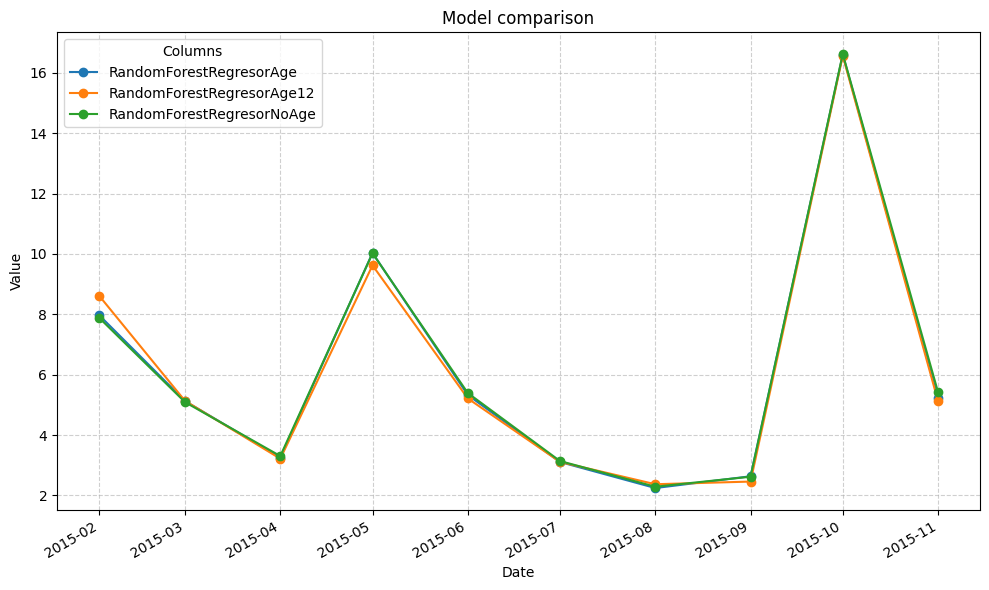

In [168]:
plot_time_dataframe(compare_24_df, 'Model comparison')